# Puncture-Aware NPCA in ns-3.49 (Google Colab)

This notebook installs **ns-3.49**, applies the patch file `puncture-aware-npca.patch` (upload it in
step 3). It implements **Non-Primary Channel
Access (NPCA)** in the ns-3 Wi-Fi stack following **IEEE P802.11bn D2.0, clause 37.18
(PPDU-based / PHYLEN NPCA)** together with the **puncture-aware** occupancy test of
*"Puncture-Aware Non-Primary Channel Access"* (VTC 2027-Spring), and runs the evaluations.

What the patch adds:
* **ns-3 Wi-Fi MAC/PHY (`src/wifi`)**: `NpcaManager` (switching conditions of 37.18.3, NPCA_TIMER,
  switch back), primary-20 MHz switching in `WifiPhy`, EDCAF state handling of 37.18.4 rule 6 and
  37.18.5 (Initial NPCA QSRC, store/restore QSRC, CW, backoff), initial Control frames on the NPCA
  primary channel (non-AP STA: **BSRP NTB Trigger frame → Multi-STA BlockAck in ICR context**;
  AP: **MU-RTS Trigger frame → CTS**; NPCA Primary Channel Indication), Beacon deferral, the
  **UHR Operation element** (NPCA Operation Parameters), and EHT non-OFDMA preamble puncturing.
* **Paper model (`src/npca`)**: Algorithm 1, 802.11be pattern tables, Eq. (4)/(5) and the DCF
  evaluation reproducing Fig. 2–4 and Table II.

**Runtime (standard CPU runtime):** build about 30–40 min (the wifi module is large), experiments
about 10 min. Set `BUILD_WIFI_TESTS = True` below to also build and run ns-3's Wi-Fi test suites
(about 40 min more).

## 0. Options

In [1]:
EXPECTED_SHA256 = '3897734226c4345c1028b96d10ddb12f50ed9c17521e09d9fa2ebebc89bd1d00'   # checksum of the patch this notebook is written for
BUILD_WIFI_TESTS = False   # True: also build and run the ns-3 Wi-Fi test suites (+~40 min)
RUNS = 5                   # seeds per point for the full-stack Wi-Fi experiment
PAPER_RUNS = 10            # seeds per point for the paper model (paper: 10)

# Re-running "Run all" continues an interrupted build by default (nothing is deleted).
# Patch file: upload puncture-aware-npca.patch when asked in step 3, or put it on Google Drive
# and give its path here, e.g. '/content/drive/MyDrive/puncture-aware-npca.patch'
PATCH_ON_DRIVE = ''

# Keep the built ns-3 on Google Drive so that a new Colab session does not have to rebuild it
# (about 125 MB; Colab asks for permission to access your Drive)
USE_DRIVE_CACHE = True
DRIVE_CACHE_DIR = '/content/drive/MyDrive/ns3-npca'

CLEAN_BUILD = False        # True: delete the build results (./ns3 clean) and rebuild from scratch
FRESH_DOWNLOAD = False     # True: delete /content/ns-3, download ns-3.49 again and re-apply the patch

## 1. Install build tools

In [2]:
!apt-get -qq update > /dev/null
!apt-get -qq install -y g++ cmake ninja-build python3-dev git > /dev/null
!g++ --version | head -1 && cmake --version | head -1 && ninja --version && nproc

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
cmake version 3.31.10
1.11.1
2


## 2. Download ns-3.49

In [4]:
import os
CACHE_TGZ = f"{DRIVE_CACHE_DIR}/ns3-npca-build.tgz"
CACHE_TAG = f"{DRIVE_CACHE_DIR}/ns3-npca-build.patch-sha256"
%cd /content
if USE_DRIVE_CACHE:
    from google.colab import drive
    drive.mount('/content/drive')
    os.makedirs(DRIVE_CACHE_DIR, exist_ok=True)
    have_cache = os.path.exists(CACHE_TGZ) and os.path.exists(CACHE_TAG)
    same_patch = have_cache and open(CACHE_TAG).read().strip() == EXPECTED_SHA256
    if FRESH_DOWNLOAD or CLEAN_BUILD:
        print("Drive cache not used (FRESH_DOWNLOAD or CLEAN_BUILD is set)")
    elif os.path.exists('/content/ns-3/ns3'):
        print("ns-3 already present in this session")
    elif same_patch:
        print("Restoring the ns-3 build from Google Drive ...")
        !tar xzf "{CACHE_TGZ}" -C /content && echo "Restored: the build step will have (almost) nothing to do"
    elif have_cache:
        print("The Drive cache was built from another patch: ns-3 is built again")
    else:
        print("No build on Google Drive yet: ns-3 is built once and then saved there")
if FRESH_DOWNLOAD or not os.path.exists('/content/ns-3/ns3'):
    !rm -rf ns-3
    !git clone -q --depth 1 --branch ns-3.49 https://gitlab.com/nsnam/ns-3-dev.git ns-3 || git clone -q --depth 1 --branch ns-3.49 https://github.com/nsnam/ns-3-dev-git.git ns-3
else:
    print("Reusing the existing /content/ns-3 (set FRESH_DOWNLOAD = True to download again)")
%cd /content/ns-3
!git log -1 --oneline

/content
Mounted at /content/drive
No build on Google Drive yet: ns-3 is built once and then saved there
Note: switching to '418210e8914e9f6bcb5cddbcc94a2cecb7853b68'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

/content/ns-3
418210e (grafted, HEAD, tag: ns-3.49) Update availability in RELEASE_NOTES.md and CHANGES.md


## 3. Get the patch file

Download **`puncture-aware-npca.patch`** from this GitHub repository, then select it when the file picker appears.

You only need to upload it once. The patch is then saved to Google Drive (`MyDrive/ns3-npca/`), and later sessions load it from there with no upload. If you turned off Drive access (`USE_DRIVE_CACHE = False`), you need to upload it again in every session.

To use a patch that is already on your Drive, set its path in `PATCH_ON_DRIVE` in cell 0.

The cell checks the patch's SHA-256 against `EXPECTED_SHA256`. If they differ, it shows a warning. It still applies the patch if the patch fits ns-3.49.

In [5]:
import os, hashlib
PATCH = '/content/puncture-aware-npca.patch'
%cd /content
import shutil
DRIVE_PATCH = f"{DRIVE_CACHE_DIR}/puncture-aware-npca.patch"
if PATCH_ON_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    shutil.copy(PATCH_ON_DRIVE, PATCH)
elif not os.path.exists(PATCH) and USE_DRIVE_CACHE and os.path.exists(DRIVE_PATCH):
    # saved on Google Drive in an earlier session: no upload needed
    shutil.copy(DRIVE_PATCH, PATCH)
    print("Patch taken from Google Drive:", DRIVE_PATCH)
if not os.path.exists(PATCH):
    from google.colab import files
    print("Select puncture-aware-npca.patch")
    uploaded = files.upload()
    name = next(iter(uploaded))          # e.g. 'puncture-aware-npca (1).patch'
    os.replace(os.path.join('/content', name), PATCH)
sha = hashlib.sha256(open(PATCH, 'rb').read()).hexdigest()
print(PATCH, os.path.getsize(PATCH), 'bytes, sha256', sha)
if sha != EXPECTED_SHA256:
    print("WARNING: this is not the patch this notebook was written for "
          "(it will still be applied if it fits ns-3.49)")
else:
    print("OK: expected patch file")
# keep a copy on Google Drive for the next sessions
if USE_DRIVE_CACHE and not PATCH_ON_DRIVE:
    if not os.path.exists(DRIVE_PATCH) or open(DRIVE_PATCH, 'rb').read() != open(PATCH, 'rb').read():
        shutil.copy(PATCH, DRIVE_PATCH)
        print("Patch saved to Google Drive:", DRIVE_PATCH)

/content
Select puncture-aware-npca.patch


Saving puncture-aware-npca.patch to puncture-aware-npca.patch
/content/puncture-aware-npca.patch 274469 bytes, sha256 3897734226c4345c1028b96d10ddb12f50ed9c17521e09d9fa2ebebc89bd1d00
OK: expected patch file
Patch saved to Google Drive: /content/drive/MyDrive/ns3-npca/puncture-aware-npca.patch


## 4. Apply the patch, configure and build

In [6]:
%cd /content/ns-3
# apply the patch only once
!if git apply --reverse --check {PATCH} 2>/dev/null; then echo "Patch already applied"; else git apply {PATCH} && echo "Patch applied"; fi
if CLEAN_BUILD:
    !./ns3 clean
    print("Build results deleted: the next build starts from scratch")
tests = "--enable-tests" if BUILD_WIFI_TESTS else "--disable-tests"
!./ns3 configure -d optimized --enable-modules="npca;wifi" --enable-examples {tests} -G Ninja 2>&1 | tail -3

/content/ns-3
Patch applied
Finished executing the following commands:
mkdir cmake-cache
/usr/local/bin/cmake -S /content/ns-3 -B /content/ns-3/cmake-cache -DCMAKE_BUILD_TYPE=release -DNS3_ASSERT=OFF -DNS3_LOG=OFF -DNS3_WARNINGS_AS_ERRORS=OFF -DNS3_NATIVE_OPTIMIZATIONS=ON -DNS3_EXAMPLES=ON -DNS3_TESTS=OFF -DNS3_ENABLED_MODULES=npca;wifi -G Ninja --warn-uninitialized


In [7]:
%cd /content/ns-3
# about 30-40 minutes on Colab; it can be interrupted (stop button) and resumed by running
# this cell (or "Run all") again: files that are already compiled are not compiled again
!./ns3 build -j $(nproc) 2>&1 | tail -3
import glob
built = glob.glob('/content/ns-3/build/src/npca/examples/ns3*-npca-wifi-mac*')
if USE_DRIVE_CACHE and built:
    print("Saving the build to Google Drive (about 1 minute) ...")
    !tar czf /content/ns3-npca-build.tgz -C /content ns-3 && cp /content/ns3-npca-build.tgz "{CACHE_TGZ}" && rm /content/ns3-npca-build.tgz
    open(CACHE_TAG, 'w').write(EXPECTED_SHA256)
    !ls -la "{DRIVE_CACHE_DIR}"
elif USE_DRIVE_CACHE:
    print("Build not finished: nothing saved to Google Drive")

/content/ns-3
[635/635] Linking CXX executable /content/ns-3/build/utils/perf/ns3.49-perf-io-optimized
Finished executing the following commands:
/usr/local/bin/cmake --build /content/ns-3/cmake-cache -j 1
Saving the build to Google Drive (about 1 minute) ...
total 123252
drwx------  2 root root      4096 Nov 25 07:41 .
drwx------ 39 root root      4096 Nov 25 07:08 ..
-rw-------  1 root root        64 Nov 25 07:41 ns3-npca-build.patch-sha256
-rw-------  1 root root 125925384 Nov 25 07:41 ns3-npca-build.tgz
-rw-------  1 root root    274469 Nov 25 07:09 puncture-aware-npca.patch


## 5. Tests (only if `BUILD_WIFI_TESTS = True`)

In [ ]:
%cd /content/ns-3
if BUILD_WIFI_TESTS:
    !./test.py --no-build -s npca
    !./test.py --no-build -s wifi-npca
    # every test suite and example test of the enabled modules (regression check)
    !./test.py --no-build 2>&1 | tail -5
else:
    print("Skipped (set BUILD_WIFI_TESTS = True in step 0 and rerun steps 4-5)")

## 6. Full-stack ns-3 Wi-Fi NPCA experiment

Two 802.11be BSSs share 80 MHz channel 42 and primary channel 36. The OBSS sends 80 MHz PPDUs that
puncture channel 44 with probability *ppunc*; BSS-A (4 STAs, uplink) uses NPCA primary channel 44.
Standard (D2.0) NPCA can never use channel 44 here, because it lies in CH_BANDWIDTH of the OBSS
PPDU; puncture-aware NPCA can when channel 44 is punctured.

In [8]:
%cd /content/ns-3
!./ns3 run --no-build "npca-wifi-mac --scheme=pa --ppunc=0.8 --simTime=2"

/content/ns-3
scheme,ppunc,run,bssA_Mbps,bssA_npca_Mbps,obss_Mbps,npca_starts,obss_ppdus,obss_punctured,ap_rejections
pa,0.800,1,111.116,19.569,68.387,146,208,172,"NPCA primary occupied (O = N \ P)=31;below minimum duration threshold=3;"


/content/ns-3
Running 90 ns-3 simulations with 2 parallel jobs ...
 ppunc   scheme  bssA_Mbps  bssA_ci  on_npca_Mbps  obss_Mbps  npca_starts_per_s  gain_vs_std_%  gain_ci
   0.0   legacy      87.26     8.64          0.00      72.05               0.00           2.82     6.40
   0.0       pa      84.95     8.44          0.00      72.01               0.00           0.00     0.00
   0.0 standard      84.95     8.44          0.00      72.01               0.00           0.00     0.00
   0.2   legacy      86.55     9.33          0.00      72.05               0.00           0.12     4.57
   0.2       pa      91.18    12.70          4.42      72.08              20.32           5.46    10.35
   0.2 standard      86.36     6.34          0.00      72.01               0.00           0.00     0.00
   0.4   legacy      86.75     9.09          0.00      72.05               0.00           3.46     7.90
   0.4       pa      93.87     3.90         10.15      72.15              44.48          12.25     9.

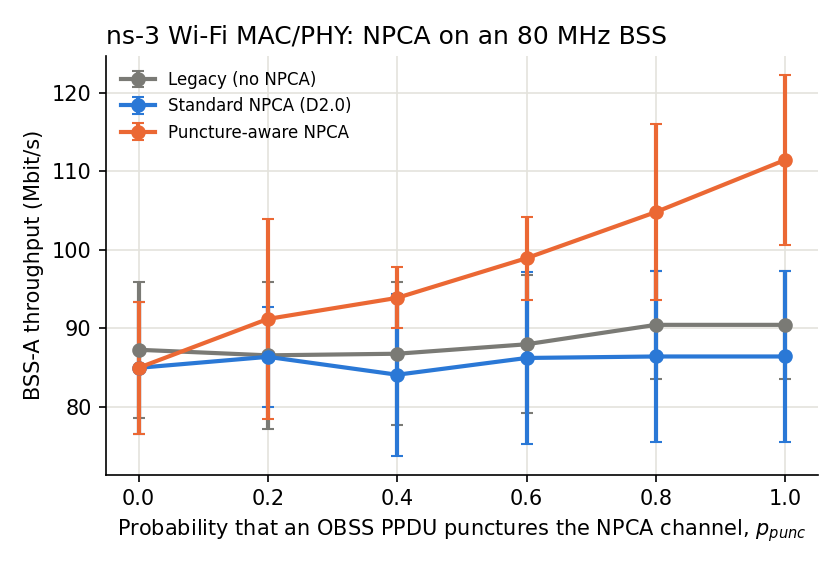

In [9]:
%cd /content/ns-3
!python3 src/npca/examples/npca_wifi_mac_sweep.py --runs {RUNS} --jobs 2 --out /content/npca-wifi-results
from IPython.display import Image, display
display(Image('/content/npca-wifi-results/npca_wifi_mac.png'))

Per-frame-type counters of one run (BSRP NTB Trigger frames, ICRs, MU-RTS, data on the NPCA channel):

In [10]:
%cd /content/ns-3
!NPCA_DEBUG=1 ./ns3 run --no-build "npca-wifi-mac --scheme=pa --ppunc=0.8 --simTime=2" 2>&1 | grep -v drop

/content/ns-3
scheme,ppunc,run,bssA_Mbps,bssA_npca_Mbps,obss_Mbps,npca_starts,obss_ppdus,obss_punctured,ap_rejections
pa,0.800,1,111.116,19.569,68.387,146,208,172,"NPCA primary occupied (O = N \ P)=31;below minimum duration threshold=3;"
ap rx trigger ntb=1 npcaInd=1: 192
ap tx CTL_BACKRESP: 508
ap tx CTL_TRIGGER: 1
obssSta RxOk: 401
sta0 rx BACKRESP 20MHz OfdmRate24Mbps NPCA: 380
sta0 rx BACKRESP 80MHz OfdmRate24Mbps primary: 307
sta0 tx NPCA CTL_BACKREQ 20MHz: 6
sta0 tx NPCA CTL_TRIGGER 20MHz: 88
sta0 tx NPCA DATA 20MHz: 70
sta0 tx primary CTL_ACK 20MHz: 2
sta0 tx primary CTL_BACKREQ 80MHz: 6
sta0 tx primary DATA 80MHz: 78
sta0 tx primary MGT_ACTION 20MHz: 1
sta0 tx primary MGT_ASSOCIATION_REQUEST 20MHz: 3


## 7. Paper model: reproduce Fig. 2, 3, 4 and Table II

In [11]:
%cd /content/ns-3
!python3 src/npca/examples/npca_reproduce.py --runs {PAPER_RUNS} --duration 15 --out /content/npca-results

/content/ns-3
Fig. 2: base scenario, sweep ppunc (rho=0.5)
  $ ns3.49-npca-paper-scenarios-optimized --scenario=base --sweep=ppunc:0,0.2,0.4,0.6,0.8 --q=1 --runs=10 --duration=15.0
  $ ns3.49-npca-paper-scenarios-optimized --scenario=base --sweep=ppunc:0,0.2,0.4,0.6,0.8 --q=0.5 --schemes=standard,pa --runs=10 --duration=15.0
  $ ns3.49-npca-paper-scenarios-optimized --scenario=base --sweep=ppunc:0,0.2,0.4,0.6,0.8 --q=1 --model=1
Fig. 3: base scenario, sweep rho (ppunc=0.4, q=0.8)
  $ ns3.49-npca-paper-scenarios-optimized --scenario=base --sweep=rho:0.2,0.3,0.4,0.5,0.6,0.7,0.8 --ppunc=0.4 --q=0.8 --runs=10 --duration=15.0
Station count (rho=0.5, ppunc=0.4, q=0.8)
  $ ns3.49-npca-paper-scenarios-optimized --scenario=base --sweep=n:2,5,10,24 --ppunc=0.4 --q=0.8 --schemes=standard,pa --runs=10 --duration=15.0
Fig. 4(a,b): 320 MHz BSS, sweep OBSS PPDU bandwidth
  $ ns3.49-npca-paper-scenarios-optimized --scenario=wideband --sweep=obssWidth:80,160,320 --schemes=legacy,standard,pa,pa-informed

,quantity,this ns-3 run,paper
0,"Sec V-A PA vs std, ppunc=0.4, q=1 (thr)",+15.7% (±0.6),+15.8%
1,"Sec V-A PA vs std, ppunc=0.8, q=1 (thr)",+30.9% (±0.8),+30.5%
2,"Sec V-A PA vs std, ppunc=0.4, q=0.5 (thr)",+7.7% (±0.4),+7.7%
3,"Sec V-A PA vs std, ppunc=0.8, q=0.5 (thr)",+15.5% (±0.8),+14.8%
4,Sec V-A std vs legacy (thr),+34.0%,+34.4%
5,"Fig 3 PA vs std, rho=0.8 (delay)",-20.9% (±0.7),-20.2%
6,"Fig 3 PA vs legacy, rho=0.8 (delay)",-64.0%,-63.6%
7,Fig 4b 320 MHz fixed (thr / delay),+0.8% (±0.1) / -3.0% (±0.4),+0.75% / -3.0%
8,Fig 4b 320 MHz informed (thr / delay),+1.7% (±0.1) / -6.2% (±0.5),+1.8% / -6.3%
9,Fig 4b 320 MHz flexible (thr / delay),+3.3% (±0.2) / -13.9% (±0.6),+3.3% / -13.9%


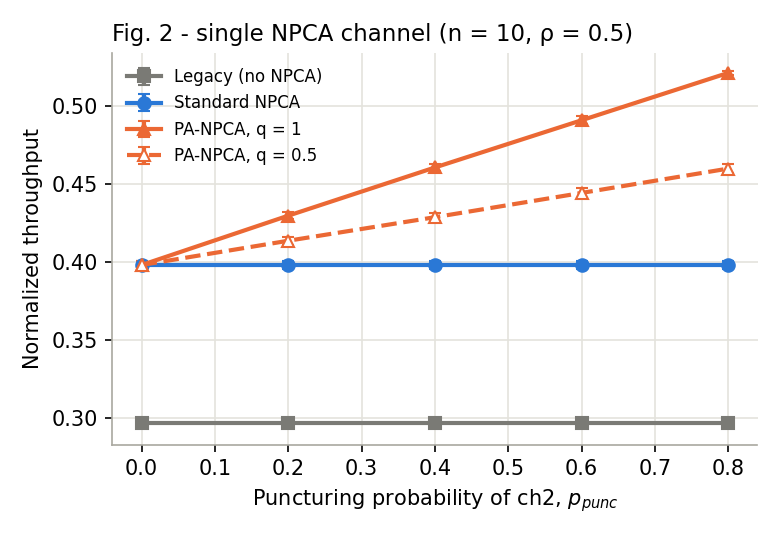

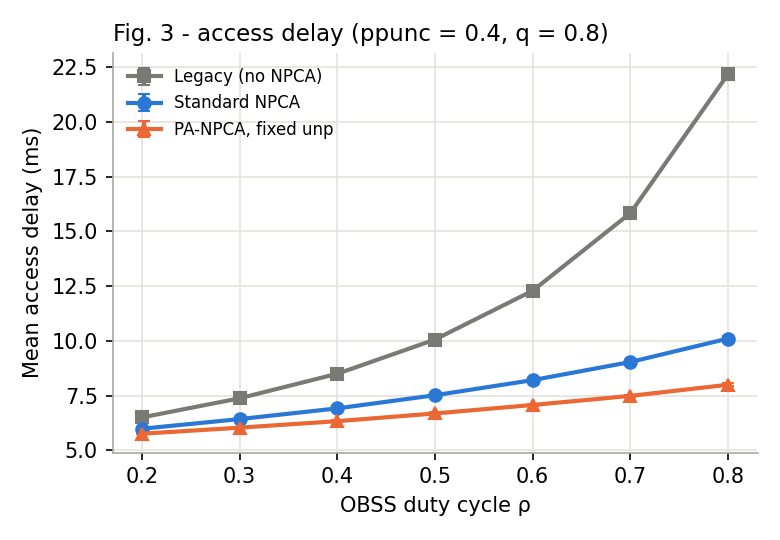

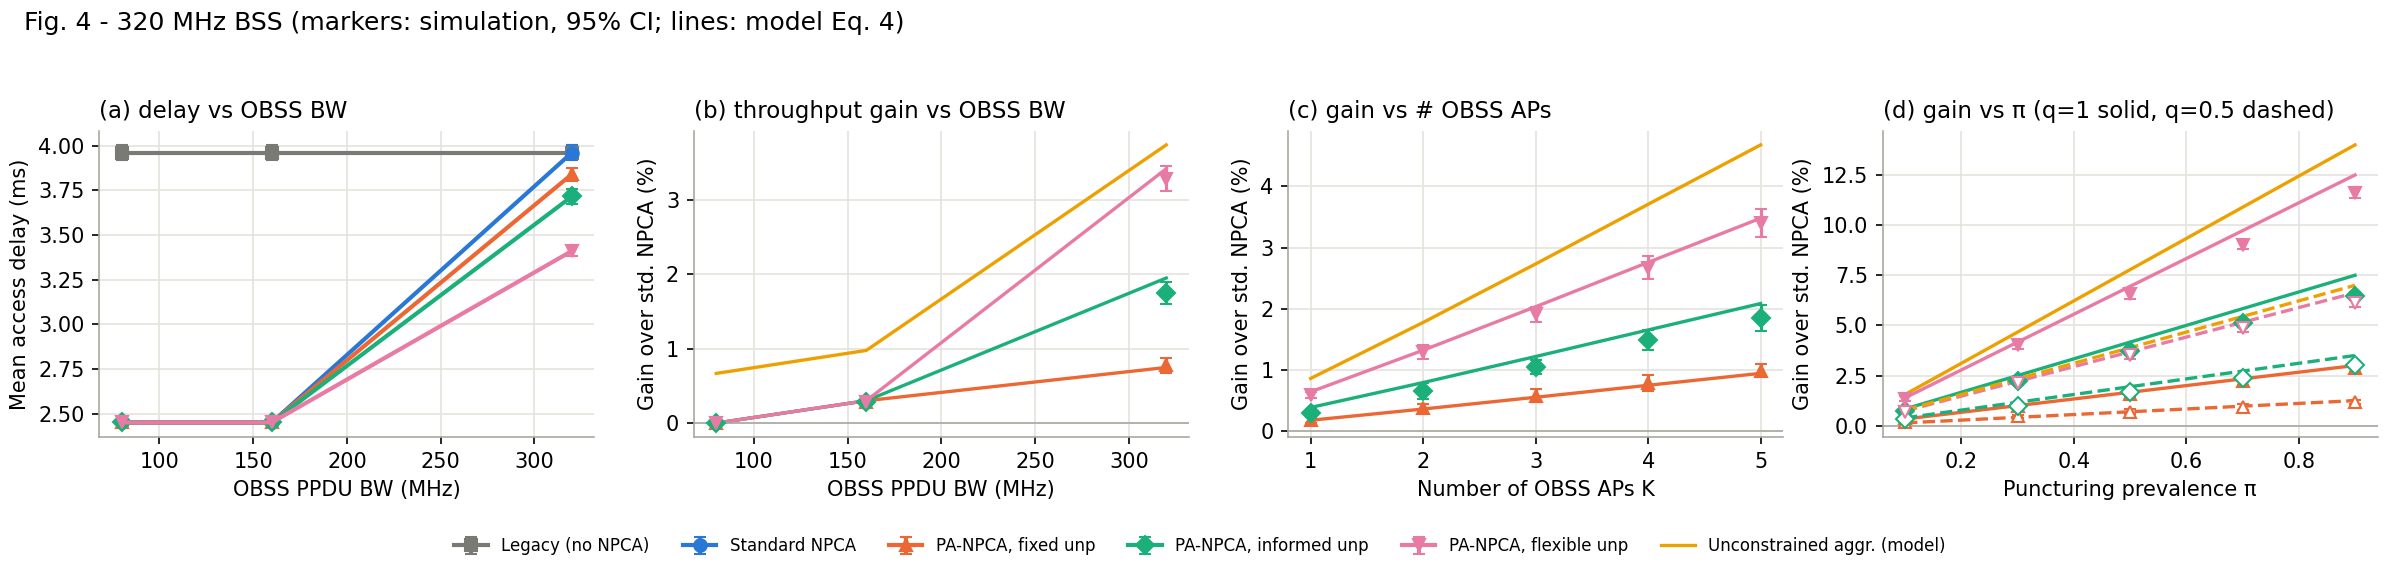

In [12]:
from IPython.display import Image, display
import pandas as pd
display(pd.read_csv('/content/npca-results/summary.csv'))
for f in ['fig2', 'fig3', 'fig4']:
    display(Image(f'/content/npca-results/{f}.png'))

## 8. NPCA parameter sensitivity experiments: distance, NMDT, and Initial NPCA QSRC

These experiments run the built `npca-wifi-mac` simulation, which uses the real ns-3 Wi-Fi MAC/PHY. Each one varies a single parameter and compares BSS-A throughput. In every run, the OBSS punctures the channel on every PPDU (`ppunc=1`).

- **(a) Distance (adjacent-channel leakage):** The distance between the OBSS AP and the BSS-A AP goes from 5 to 20 m. At short distances, the OBSS signal leaks into the punctured channel (−20 dBr residual power). The AP's per-20 MHz CCA then reports busy, so the AP withholds the ICR and the NPCA gain shrinks. This experiment compares Standard NPCA with Puncture-aware NPCA.
- **(b) NMDT (minimum duration threshold):** NPCA starts only if the remaining OBSS PPDU duration exceeds `512 + NMDT×128 µs`. The OBSS PPDUs are kept short (`obssBurst=16`, about 1.3 ms) while NMDT goes from 0 to 15. A larger threshold should leave fewer NPCA opportunities.
- **(c) Initial NPCA QSRC:** This sets the initial contention window on the NPCA channel, `CW = 2^Q·(CWmin+1)−1`. QSRC goes from 0 to 3 to show how the backoff size affects NPCA throughput.

**Plots:** The solid lines show total BSS-A throughput with 95% confidence intervals. The dashed line shows the part of that throughput sent on the NPCA channel.
**Settings:** At the top of the cell, you can change `EXP_RUNS` (seeds per point), `EXP_SIMTIME` (simulated time per run), and the list of values for each sweep.
**Output:** The CSV files and `own_experiments.png` are saved in `/content/npca-own-experiments/`.
**Note:** Run cell 4 (the build) first. With the default settings (3 seeds), this cell takes a few minutes on Colab.

distance: 30 runs ...
nmdt: 15 runs ...
qsrc: 12 runs ...


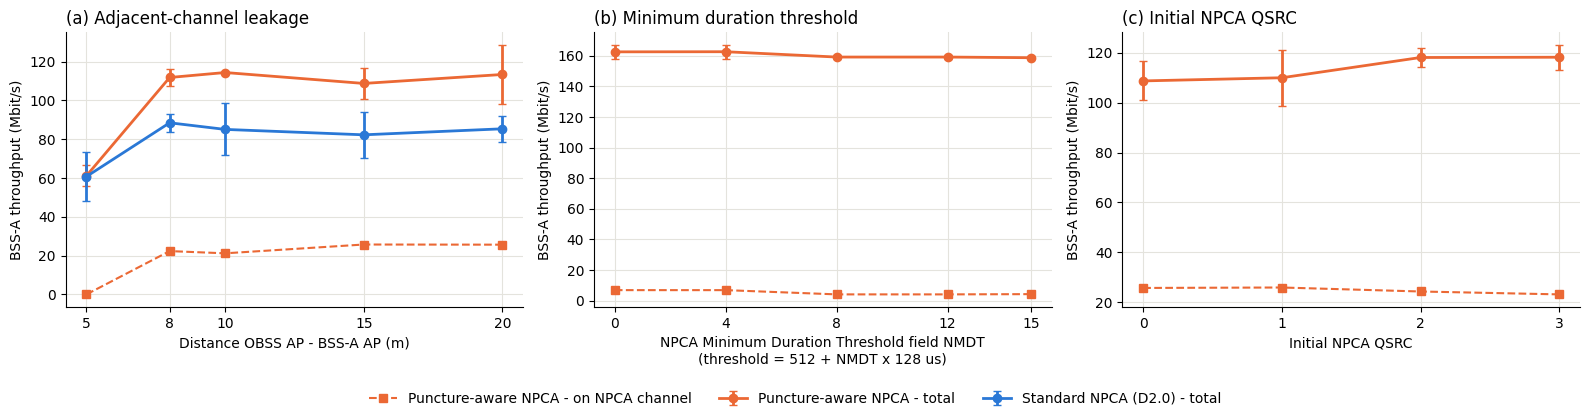

(a) distance


,distance,scheme,bssA_Mbps,bssA_npca_Mbps,obss_Mbps,npca_starts,bssA_ci95
0,5,pa,61.1,0.0,71.9,192.0,5.5
1,5,standard,60.8,0.0,71.9,0.0,12.5
2,8,pa,111.8,22.3,72.0,180.7,4.4
3,8,standard,88.5,0.0,71.8,0.0,4.6
4,10,pa,114.4,21.2,71.8,172.0,0.5
5,10,standard,85.1,0.0,71.7,0.0,13.4
6,15,pa,108.8,25.7,71.9,185.0,7.8
7,15,standard,82.3,0.0,71.8,0.0,11.8
8,20,pa,113.4,25.6,71.9,186.0,15.3
9,20,standard,85.4,0.0,71.8,0.0,6.7


(b) NMDT


,nmdt,scheme,bssA_Mbps,bssA_npca_Mbps,obss_Mbps,npca_starts,bssA_ci95
0,0,pa,162.6,6.8,23.9,139.3,4.5
1,4,pa,162.7,6.8,23.9,141.0,4.6
2,8,pa,159.2,4.0,23.9,41.3,1.6
3,12,pa,159.2,4.0,23.9,41.3,1.6
4,15,pa,158.8,4.2,23.9,42.3,0.9


(c) Initial NPCA QSRC


,qsrc,scheme,bssA_Mbps,bssA_npca_Mbps,obss_Mbps,npca_starts,bssA_ci95
0,0,pa,108.8,25.7,71.9,185.0,7.8
1,1,pa,110.0,25.9,71.8,180.0,11.2
2,2,pa,118.2,24.3,71.9,170.0,3.9
3,3,pa,118.3,23.1,71.8,168.0,5.0


CSV files and the figure are in /content/npca-own-experiments


In [13]:
import glob, io, os, subprocess
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import pandas as pd

# ---------------- settings (change freely) ----------------
EXP_RUNS = 3          # seeds per point (more seeds: narrower confidence intervals)
EXP_SIMTIME = 2.0     # simulated seconds per run
EXP_JOBS = os.cpu_count() or 2
DISTANCES = [5, 8, 10, 15, 20]          # m, OBSS AP <-> BSS-A AP (leakage into ch44)
NMDT_VALUES = [0, 4, 8, 12, 15]         # minimum duration = 512 + NMDT x 128 us
NMDT_OBSS_BURST = 16                    # packets per OBSS burst: shorter OBSS PPDUs (~1.3 ms)
QSRC_VALUES = [0, 1, 2, 3]              # Initial NPCA QSRC
OUT = '/content/npca-own-experiments'
# -----------------------------------------------------------

os.makedirs(OUT, exist_ok=True)
BIN = sorted(glob.glob('/content/ns-3/build/src/npca/examples/ns3*-npca-wifi-mac*'))[0]
COLS = ["scheme", "ppunc", "run", "bssA_Mbps", "bssA_npca_Mbps", "obss_Mbps", "npca_starts",
        "obss_ppdus", "obss_punctured", "ap_rejections"]


def sweep(name, values, schemes, make_args):
    # run every (value, scheme, seed) and return a DataFrame
    jobs = [(v, s, r) for v in values for s in schemes for r in range(1, EXP_RUNS + 1)]

    def one(job):
        v, s, r = job
        cmd = [BIN, f"--scheme={s}", f"--run={r}", f"--simTime={EXP_SIMTIME}", "--header=0"]
        cmd += make_args(v)
        out = subprocess.run(cmd, check=True, capture_output=True, text=True).stdout
        row = pd.read_csv(io.StringIO(out), names=COLS).iloc[0].to_dict()
        row[name] = v
        return row

    print(f"{name}: {len(jobs)} runs ...", flush=True)
    with ThreadPoolExecutor(EXP_JOBS) as ex:
        df = pd.DataFrame(list(ex.map(one, jobs)))
    df.to_csv(f"{OUT}/{name}.csv", index=False)
    return df


def summarize(df, name):
    g = df.groupby([name, "scheme"])
    s = g[["bssA_Mbps", "bssA_npca_Mbps", "obss_Mbps", "npca_starts"]].mean()
    ci = 1.96 * g["bssA_Mbps"].std(ddof=1).fillna(0) / g["bssA_Mbps"].count() ** 0.5
    s["bssA_ci95"] = ci
    return s.reset_index()


COLORS = {"standard": "#2a78d6", "pa": "#eb6834", "legacy": "#7a7a75"}
LABELS = {"standard": "Standard NPCA (D2.0)", "pa": "Puncture-aware NPCA", "legacy": "Legacy"}


def panel(ax, s, name, xlabel, title):
    for sc in s.scheme.unique():
        r = s[s.scheme == sc]
        ax.errorbar(r[name], r.bssA_Mbps, yerr=r.bssA_ci95, color=COLORS[sc], marker="o", lw=2,
                    capsize=3, label=LABELS[sc] + " - total")
        if sc == "pa":
            ax.plot(r[name], r.bssA_npca_Mbps, color=COLORS[sc], marker="s", ls="--", lw=1.5,
                    label=LABELS[sc] + " - on NPCA channel")
    ax.set_xticks(sorted(s[name].unique()))
    ax.set_xlabel(xlabel)
    ax.set_ylabel("BSS-A throughput (Mbit/s)")
    ax.set_title(title, loc="left")
    ax.grid(True, color="#e4e3dd")
    ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)


# (a) distance: adjacent-channel leakage of the OBSS PPDU into the punctured channel 44
a = sweep("distance", DISTANCES, ["standard", "pa"],
          lambda d: ["--ppunc=1", f"--distance={d}"])
# (b) NPCA minimum duration threshold, with shorter OBSS PPDUs
b = sweep("nmdt", NMDT_VALUES, ["pa"],
          lambda n: ["--ppunc=1", f"--obssBurst={NMDT_OBSS_BURST}",
                     f"--ns3::NpcaManager::MinDurationThreshold={n}"])
# (c) Initial NPCA QSRC
c = sweep("qsrc", QSRC_VALUES, ["pa"],
          lambda q: ["--ppunc=1", f"--ns3::NpcaManager::InitialQsrc={q}"])

sa, sb, sc_ = summarize(a, "distance"), summarize(b, "nmdt"), summarize(c, "qsrc")
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
panel(axs[0], sa, "distance", "Distance OBSS AP - BSS-A AP (m)",
      "(a) Adjacent-channel leakage")
panel(axs[1], sb, "nmdt", "NPCA Minimum Duration Threshold field NMDT\n(threshold = 512 + NMDT x 128 us)",
      "(b) Minimum duration threshold")
panel(axs[2], sc_, "qsrc", "Initial NPCA QSRC", "(c) Initial NPCA QSRC")
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(f"{OUT}/own_experiments.png", dpi=150)
plt.show()

pd.set_option("display.precision", 1)
for title, s in (("(a) distance", sa), ("(b) NMDT", sb), ("(c) Initial NPCA QSRC", sc_)):
    print(title)
    display(s)
print("CSV files and the figure are in", OUT)

## 9. Download the results

In [14]:
import os
from google.colab import files

# Bundle the result folders that exist (cells you skipped are left out)
dirs = [d for d in ["npca-results", "npca-wifi-results", "npca-own-experiments"]
        if os.path.isdir(f"/content/{d}")]
print("Included:", dirs)

!cd /content && rm -f npca-results.zip && zip -qr npca-results.zip {" ".join(dirs)}

# Also keep a copy on Drive if it is mounted
if os.path.isdir("/content/drive/MyDrive"):
    os.makedirs("/content/drive/MyDrive/ns3-npca", exist_ok=True)
    !cp /content/npca-results.zip /content/drive/MyDrive/ns3-npca/
    print("Copied to Drive: MyDrive/ns3-npca/npca-results.zip")

files.download("/content/npca-results.zip")

Included: ['npca-results', 'npca-wifi-results', 'npca-own-experiments']
Copied to Drive: MyDrive/ns3-npca/npca-results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>